<a href="https://colab.research.google.com/github/ab110404/MAT422/blob/main/HW3.2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HW 3.2

3.2.1. Limits and continuity

- In this section, I will demonstrate Euclidean distance, open balls, and continuity using Python

In [1]:
import numpy as np
import matplotlib.pyplot as plt
x = np.array([3, 4])
distance = np.linalg.norm(x)
print("Point:", x)
print("Euclidean norm:", distance)

Point: [3 4]
Euclidean norm: 5.0


- I will now create an open ball centered at (0,0) with radius 2.

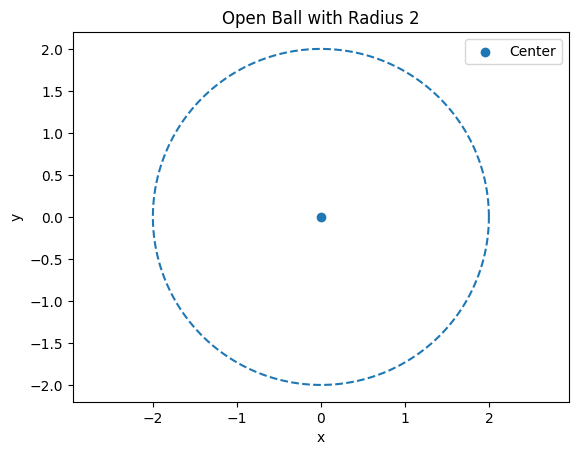

In [2]:
theta = np.linspace(0, 2*np.pi, 200)
r = 2
x_circle = r * np.cos(theta)
y_circle = r * np.sin(theta)
plt.plot(x_circle, y_circle, '--')
plt.scatter(0, 0, label="Center")
plt.axis("equal")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Open Ball with Radius 2")
plt.legend()
plt.show()

- A limit point is a point where other points in a set can get arbitrarily close.
- For example, consider the sequence
x_n = 1/n.
- As n increases, the values approach 0.
- Therefore, 0 is a limit point of the set.

First five values: [1.         0.5        0.33333333 0.25       0.2       ]
Last value: 0.01


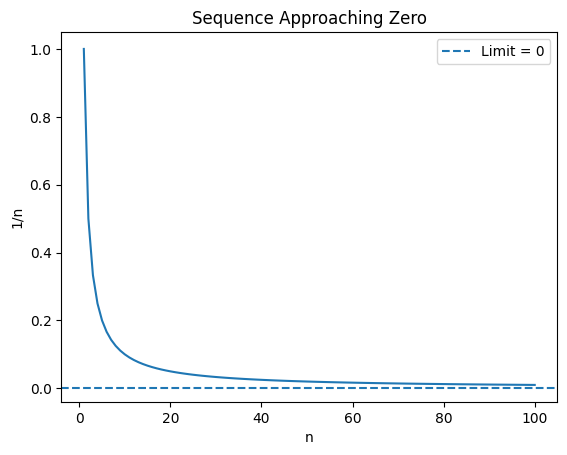

In [3]:
n = np.arange(1, 101)
x_n = 1/n
print("First five values:", x_n[:5])
print("Last value:", x_n[-1])
plt.plot(n, x_n)
plt.axhline(0, linestyle="--", label="Limit = 0")
plt.xlabel("n")
plt.ylabel("1/n")
plt.title("Sequence Approaching Zero")
plt.legend()
plt.show()

- A function is continuous at a point if the limit of the function equals its value at that point.

In [4]:
def f(x):
  return x**2
x0 = 2
h = np.array([0.1, 0.01, 0.001, 0.0001])
values = f(x0 + h)
print("f(2) =", f(x0))
print("Values approaching f(2):")
print(values)
print("Differences:")
print(np.abs(values - f(x0)))

f(2) = 4
Values approaching f(2):
[4.41       4.0401     4.004001   4.00040001]
Differences:
[4.1000e-01 4.0100e-02 4.0010e-03 4.0001e-04]


Conclusion:
- In this section, I explored limits and continuity using Python. These examples help illustrate the mathematical concepts shown in section 3.2.1

3.2.2. Derivatives
- In this example, I will use Python to approximate the derivative of f(x) = x^2 at x = 2. The exact derivative is f'(x) = 2x, so f'(2) = 4.

In [5]:
def f(x):
  return x**2
x0 = 2
print("f(2) =", f(x0))
print("Exact derivative at x = 2:", 2*x0)

f(2) = 4
Exact derivative at x = 2: 4


- The derivative can be approximated using the difference quotient: [f(x0+h) - f(xo)]/h.
- As h becomes smaller, the approximation should approach the exact derivative.
- I will now test several values of h to observe this behavior.

In [6]:
h_values = [0.1, 0.01, 0.001, 0.0001]
for h in h_values:
  derivative = (f(x0 + h) - f(x0)) / h
  print(f"h = {h}, derivative = {derivative:.6f}")

h = 0.1, derivative = 4.100000
h = 0.01, derivative = 4.010000
h = 0.001, derivative = 4.001000
h = 0.0001, derivative = 4.000100


- I wil now compare the numerical approximation with the exact derivative to calculate the error

In [7]:
exact_derivative = 4
for h in h_values:
  approximation = (f(x0 + h) - f(x0)) / h
  error = abs(exact_derivative - approximation)
  print(f"h = {h}, error = {error:.6f}")

h = 0.1, error = 0.100000
h = 0.01, error = 0.010000
h = 0.001, error = 0.001000
h = 0.0001, error = 0.000100


- I will now plot the function and its tangent line to visualize the derivative

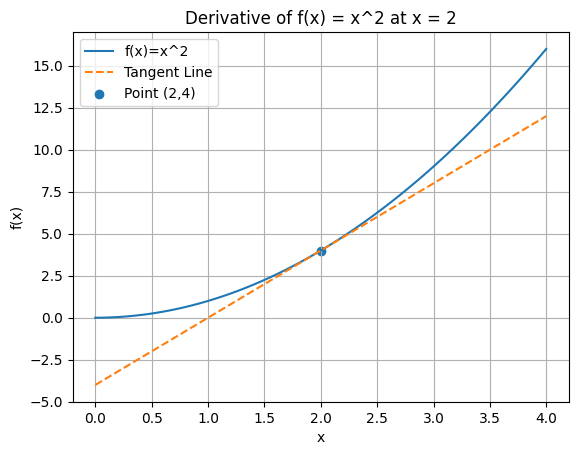

In [9]:
x = np.linspace(0, 4, 100)
y = f(x)
tangent = f(x0) + 4*(x - x0)
plt.plot(x, y, label="f(x)=x^2")
plt.plot(x, tangent, "--", label="Tangent Line")
plt.scatter(x0, f(x0), label="Point (2,4)")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Derivative of f(x) = x^2 at x = 2")
plt.legend()
plt.grid(True)
plt.show()

Conclusion:
- In this section, I used Python to approximate the derivative of f(x) = x^2 at x=2. The numerical approximations approached the exact derivative of 4 as h became smaller. The graph demonstrated that the derivative represents the slope of the tangent line. This example verifies the definiton of the derivative introduced in section 3.2.2.

3.2.3. Taylor’s theorem
- In this example, I will approximate f(x)=e^x around a=0 and compare the approximation with the actual function.

In [10]:
def f(x):
  return np.exp(x)
a = 0
b = 0.5
actual = f(b)
print("Expansion point a =", a)
print("Evaluation point b =", b)
print("Actual f(0.5) =", actual)

Expansion point a = 0
Evaluation point b = 0.5
Actual f(0.5) = 1.6487212707001282


- The first-order approximation around a = 0 is T1(x) = 1 + x

In [11]:
first_order = 1 + b
error1 = abs(actual - first_order)
print("First-order approximation:", first_order)
print("Absolute error:", error1)

First-order approximation: 1.5
Absolute error: 0.1487212707001282


- Since f(x) = e^x, all its derivatives equal e^x. At a=0, the second-order approximation becomes T2(x) = 1 + x + x^2/2
- I will now compare this approximation with the actual value.

In [12]:
second_order = 1 + b + (b**2)/2
error2 = abs(actual - second_order)
print("Second-order approximation:", second_order)
print("Absolute error:", error2)

Second-order approximation: 1.625
Absolute error: 0.023721270700128194


- The second-order Taylor polynomial should provide a better approximation because it includes an additional term. I will compare the absolute errors to verify this.

In [13]:
print("Actual value:", actual)
print("First-order approximation:", first_order)
print("Second-order approximation:", second_order)
print("\nFirst-order error:", error1)
print("Second-order error:", error2)
print("nIs the second-order error smaller?", error2 < error1)

Actual value: 1.6487212707001282
First-order approximation: 1.5
Second-order approximation: 1.625

First-order error: 0.1487212707001282
Second-order error: 0.023721270700128194
nIs the second-order error smaller? True


- I wil now plot the original function and both Taylor approximations. The graph will show how closely the Taylor polynomials approximate the exponential function near x=0.

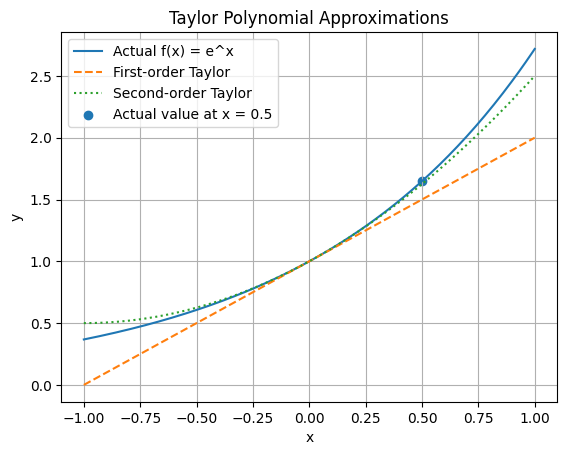

In [14]:
x = np.linspace(-1, 1, 200)
y_actual = np.exp(x)
y_first = 1 + x
y_second = 1 + x + x**2/2
plt.plot(x, y_actual, label="Actual f(x) = e^x")
plt.plot(x, y_first, "--", label="First-order Taylor")
plt.plot(x, y_second, ":", label="Second-order Taylor")
plt.scatter(b, actual, label="Actual value at x = 0.5")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Taylor Polynomial Approximations")
plt.legend()
plt.grid(True)
plt.show()

- I will now calculate the remainder and verify that the corresponding value of 𝜉 lies between 0 and 0.5

In [15]:
remainder = actual - first_order
xi = np.log(2 * remainder / (b - a)**2)
verified_remainder = ((b - a)**2 / 2) * np.exp(xi)
print("Actual remainder:", remainder)
print("Calculated xi:", xi)
print("Verified remainder:", verified_remainder)
print("Is xi between a and b?", a < xi < b)
print("Does the remainder match?", np.isclose(remainder, verified_remainder))

Actual remainder: 0.1487212707001282
Calculated xi: 0.1737601503194649
Verified remainder: 0.1487212707001282
Is xi between a and b? True
Does the remainder match? True


Conclusion:
- In this section, I used Python to demonstrate Taylor's theorem by approximating f(x) = e^x around a = 0.
- Overall, all these examples demonstrated each section in the books and included graphs to help visualize/showcase the examples.